In [1]:
import emcee
import corner
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
from uncertainties import ufloat
from uncertainties.umath import *
from uncertainties import unumpy as unp
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM
cosmo=FlatLambdaCDM(70, 0.3)
from functions.statistics_functions import chi_squared
from functions.load_data_and_var import generate_nfws_from_combined_dataset_werr

In [2]:
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    combined_data = pickle.load(f)
low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_94572/3620387234.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()


In [3]:
low_z_data

,OName,Name,L500,z_y
2,RXCJ0003.8+0203,A2700,0.846881,0.0924
3,RXCJ0006.0-3443,A2721,1.809494,0.1147
6,RXCJ0011.3-2851,A2734,1.086002,0.0620
9,RXCJ0013.6-1930,A0013,1.236332,0.0940
10,RXCJ0014.3-6604,A2746,2.827248,0.1599
...,...,...,...,...
541,RXCJ2344.2-0422,,1.852614,0.0786
543,RXCJ2347.7-2808,A4038,1.029501,0.0300
547,RXCJ2354.2-1024,A2670,1.336537,0.0765
549,RXCJ2357.0-3445,A4059,1.629622,0.0475


In [4]:
reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())
#data = data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)
#data['Name'].values.strip()
reflex_data = reflex_data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)[['RXC', 'Flux', 'e_Flux', 'ObsLum', 'LumCor', 'z']].dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_94572/2434024660.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())


In [5]:
reflex_data

,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.1-0605,4.497,12.4,6.395,6.876,0.2320
1,RXCJ0003.2-3555,7.537,17.8,0.421,0.478,0.0490
2,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
3,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
4,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620
...,...,...,...,...,...,...
442,RXCJ2351.6-2605,9.295,10.1,12.422,13.651,0.2264
443,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765
444,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475
445,RXCJ2359.3-6042,4.544,20.5,1.080,1.149,0.0989


In [6]:
reflex_data.head()

,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.1-0605,4.497,12.4,6.395,6.876,0.2320
1,RXCJ0003.2-3555,7.537,17.8,0.421,0.478,0.0490
2,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
3,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
4,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620


In [7]:
comb = pd.merge(low_z_data, reflex_data, left_on='OName', right_on='RXC', how='inner', sort=True)

In [8]:
comb

,OName,Name,L500,z_y,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.8+0203,A2700,0.846881,0.0924,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
1,RXCJ0006.0-3443,A2721,1.809494,0.1147,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
2,RXCJ0011.3-2851,A2734,1.086002,0.0620,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620
3,RXCJ0013.6-1930,A0013,1.236332,0.0940,RXCJ0013.6-1930,6.071,11.3,1.285,1.353,0.0940
4,RXCJ0014.3-6604,A2746,2.827248,0.1599,RXCJ0014.3-6604,4.485,13.8,2.907,3.160,0.1599
...,...,...,...,...,...,...,...,...,...,...
168,RXCJ2344.2-0422,,1.852614,0.0786,RXCJ2344.2-0422,12.638,7.4,1.855,2.061,0.0786
169,RXCJ2347.7-2808,A4038,1.029501,0.0300,RXCJ2347.7-2808,49.578,3.8,1.014,1.127,0.0300
170,RXCJ2354.2-1024,A2670,1.336537,0.0765,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765
171,RXCJ2357.0-3445,A4059,1.629622,0.0475,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475


In [9]:
ONames = (comb['OName'].tolist())

In [10]:
# calculate flux with variance in watts
flux_arr=comb['Flux'].to_numpy()*1e-15 # to get in watts
eflux_arr=comb['e_Flux'].to_numpy()
flux_var=np.array([ufloat(flux_arr[i],eflux_arr[i]*flux_arr[i]/100) for i in range(len(flux_arr))])

In [11]:
# Calculate Lobs from flux with variance

d_L = cosmo.comoving_distance(comb['z_y']).to(u.m).value #(return meters)
#originally in units u.W*1e-15/u.m**2 * Mpc**2
Lobs_calc=(flux_var*4*np.pi*d_L**2) * 1e-37 

#Lobs_calc #now in units of 1e37 W
Lobs_err = [L.std_dev for L in Lobs_calc]
#Lobs_err
Lobs_calc

array([0.745922576900713+/-0.14023344445733404,
       1.5962288643873468+/-0.21708712555667914,
       0.9850814005299323+/-0.0886573260476939,
       1.1271051139128871+/-0.12736287787215625,
       2.333867767423409+/-0.3220737519044305,
       2.4135326772236376+/-0.2920374539440601,
       0.45618706030144873+/-0.04425014484924054,
       1.8425238329482687+/-0.3150715754341539,
       1.2636774736720755+/-0.16806910399838607,
       1.2026954179964795+/-0.09501293802172188,
       4.890977692536981+/-0.1565112861611834,
       2.3879872138694673+/-0.2340227469592078,
       1.4123668858975584+/-0.0748554449525706,
       1.3174099397720227+/-0.08826646596472552,
       0.4175108555327666+/-0.04091606384221112,
       0.17222891932443235+/-0.01377831354595459,
       0.45404892283675474+/-0.042226549823818196,
       0.7175482809428992+/-0.05668631419448903,
       1.7091148865220904+/-0.27345838184353455,
       3.1578969342457186+/-0.42315818918892634,
       1.4289856888365742+

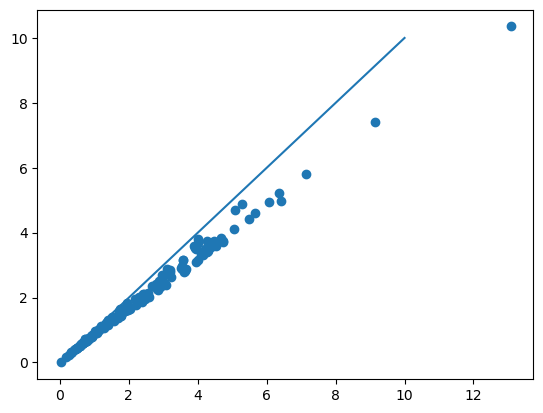

In [12]:
plt.scatter(comb['ObsLum'], [L.nominal_value for L in Lobs_calc])
plt.plot([0,10], [0,10])

In [13]:
# MCMC: L_o=(L_c - b)/m 
# change to L_o=(L500-b)/m
L_obs_data = comb['ObsLum']
L_obs_var=[L.std_dev for L in Lobs_calc]
#L_cor=comb['LumCor']
L500=comb['L500']

Text(0, 0.5, 'L500')

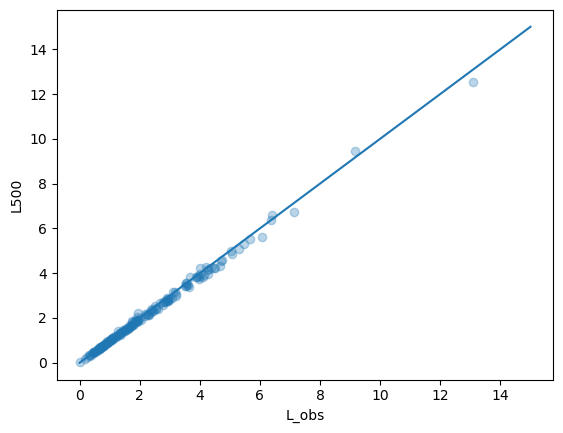

In [14]:
plt.scatter(L_obs_data, L500, alpha=0.3)
plt.plot(np.linspace(0,15), np.linspace(0,15))
plt.xlabel('L_obs')
plt.ylabel('L500')

In [15]:
def log_lik(p0, L_c, obs, var):
    m=p0[0]
    if np.abs(m)<0.00001:
        return -np.inf
    b=p0[1]
    if np.abs(m)>10 or np.abs(b)>10:
        return -np.inf
    pred=(L_c-b)/m
    return -1*chi_squared(pred, obs, var)/2

In [16]:
p0=[1, 0]
log_lik(p0, L500, L_obs_data, np.array(L_obs_var))

-23.439121240851986

In [17]:
ndim=2
nwalkers = 32
guess=(1, 0)
p0 = guess+np.random.normal(scale=0.1, size=(nwalkers, ndim))
p0

array([[ 0.96813259, -0.09050046],
       [ 1.09869208,  0.14514316],
       [ 1.00228918, -0.05106525],
       [ 1.10016271, -0.12939584],
       [ 0.91613108, -0.0764592 ],
       [ 1.03879753, -0.10737642],
       [ 0.97115598,  0.01821288],
       [ 1.05013566, -0.07913511],
       [ 0.95493881, -0.02904889],
       [ 1.03346505, -0.16464499],
       [ 0.85064956, -0.11339462],
       [ 1.01211093, -0.15207346],
       [ 1.01017381,  0.09099191],
       [ 1.08565013,  0.21152822],
       [ 1.07411441,  0.16264826],
       [ 1.17435618, -0.06677707],
       [ 0.97199981,  0.11506021],
       [ 0.83602905, -0.039522  ],
       [ 1.0267519 ,  0.00529906],
       [ 0.97051419,  0.01016444],
       [ 0.96618276,  0.05412399],
       [ 1.09322697,  0.04599143],
       [ 1.18411793, -0.16973143],
       [ 0.92840511, -0.18087845],
       [ 0.94378345, -0.05444859],
       [ 0.95200242,  0.05250082],
       [ 0.9044022 ,  0.10398574],
       [ 1.1258814 , -0.07483899],
       [ 1.00281208,

In [18]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_lik, args=[L500, L_obs_data, np.array(L_obs_var)])

In [19]:
state = sampler.run_mcmc(p0, 100, progress=True)
sampler.reset()

100%|█████████████████████████████████████████| 100/100 [00:01<00:00, 85.74it/s]


In [20]:
sampler.run_mcmc(state, 5000, progress=True)

100%|███████████████████████████████████████| 5000/5000 [00:58<00:00, 85.94it/s]


State([[ 9.78857827e-01 -1.25291109e-03]
 [ 9.73754878e-01  1.34425024e-02]
 [ 9.64359055e-01  1.31404919e-02]
 [ 9.65289898e-01  1.24655840e-02]
 [ 9.61311319e-01  1.40700367e-02]
 [ 9.60177714e-01  8.70392543e-03]
 [ 9.76849303e-01  4.63081926e-03]
 [ 9.69785081e-01  3.01545106e-03]
 [ 9.77569414e-01  1.58580616e-03]
 [ 9.88567358e-01  4.52501763e-04]
 [ 9.77961061e-01  8.12943474e-03]
 [ 9.78003429e-01  1.02887820e-03]
 [ 9.75527654e-01  3.81823799e-03]
 [ 9.68488948e-01 -8.23989362e-04]
 [ 9.67174731e-01  7.58093320e-03]
 [ 9.59125867e-01  1.79497583e-02]
 [ 9.58244289e-01  1.97493560e-02]
 [ 9.79811906e-01  5.86696743e-03]
 [ 9.70928915e-01  6.17791266e-03]
 [ 9.72676650e-01  5.07161718e-04]
 [ 9.82478906e-01  1.30159226e-02]
 [ 9.89576674e-01 -8.77053723e-03]
 [ 9.72511988e-01  2.32655251e-03]
 [ 9.80426240e-01  4.54956648e-03]
 [ 9.79141800e-01  1.91881650e-03]
 [ 9.81482456e-01 -3.37644870e-03]
 [ 9.75036839e-01  8.54419416e-03]
 [ 9.78107881e-01  2.36796663e-03]
 [ 9.77112969e

In [21]:
flat_samples = sampler.get_chain(flat=True)
print(flat_samples.shape)

(160000, 2)


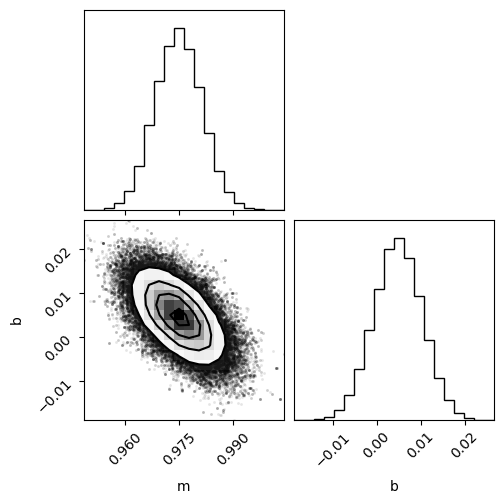

In [22]:
fig = corner.corner(flat_samples, labels=['m', 'b']) 

In [23]:
tau = sampler.get_autocorr_time()
print(tau)

[31.03316505 29.46680142]


In [24]:
np.median(flat_samples[:,0]), np.median(flat_samples[:,1])

(0.974780844729935, 0.004788933772206754)

In [25]:
m_err=np.var(flat_samples[:,0]) # var=mean((p-pmean)**2)
m_err

4.201575282430036e-05

In [26]:
b_err=np.var(flat_samples[:,1])
b_err

3.011553248625261e-05

In [27]:
m_uf=ufloat(np.median(flat_samples[:,0]), np.var(flat_samples[:,0]))
b_uf=ufloat(np.median(flat_samples[:,1]), np.var(flat_samples[:,1]))

m_uf, b_uf # uncertainty too small??

(0.974780844729935+/-4.201575282430036e-05,
 0.004788933772206754+/-3.011553248625261e-05)

In [28]:
# get L500 based on this relationship that we found
L_obs_uf=unp.uarray(comb['ObsLum'], [L.std_dev for L in Lobs_calc])

L500_pred=m_uf*L_obs_uf+b_uf

In [29]:
L500_uf=unp.uarray(comb['L500'], [L.std_dev for L in L500_pred])
L500_uf

array([0.846881+/-0.13669688348514952, 1.809494+/-0.21161238843718544,
       1.086002+/-0.08642148053584012, 1.236332+/-0.12415090907157772,
       2.827248+/-0.3139513491498093, 2.872451+/-0.28467254387966257,
       0.49467+/-0.04313420908237525, 2.164603+/-0.3071257524391626,
       1.404549+/-0.1638305579136705, 1.253723+/-0.09261681450847083,
       5.100085+/-0.15256436879219495, 2.734146+/-0.2281209230304087,
       1.437223+/-0.0729676874773413, 1.460216+/-0.08604048676774409,
       0.491051+/-0.03988421124661566, 0.181484+/-0.013430871986481248,
       0.467516+/-0.0411616480308783, 0.763259+/-0.05525675111048183,
       2.010759+/-0.26656200746454517, 4.237381+/-0.4124865326204333,
       1.768408+/-0.24933768296966247, 0.561478+/-0.06528887092158957,
       0.669697+/-0.08460658862118932, 0.334315+/-0.1442250524083605,
       1.027456+/-0.0836764265437153, 3.815928+/-0.13353711626028406,
       0.593611+/-0.052935900967806, 1.467361+/-0.09599614929217118,
       3.817746+/

In [30]:
# grab predicted L errs
L_errs = [L.std_dev for L in L500_pred]
len(L_errs)

173

In [31]:
dict_name_err = dict(zip(comb['OName'], L_errs))

In [32]:
dict_name_err['RXCJ0011.3-2851']

0.08642148053584012

In [33]:
import pickle
with open('data/REFLEX_lowz_errs.p', 'wb') as fp:
    pickle.dump(dict_name_err, fp)

In [34]:
dict_name_err

{'RXCJ0003.8+0203': 0.13669688348514952,
 'RXCJ0006.0-3443': 0.21161238843718544,
 'RXCJ0011.3-2851': 0.08642148053584012,
 'RXCJ0013.6-1930': 0.12415090907157772,
 'RXCJ0014.3-6604': 0.3139513491498093,
 'RXCJ0020.7-2542': 0.28467254387966257,
 'RXCJ0025.5-3302': 0.04313420908237525,
 'RXCJ0027.3-5015': 0.3071257524391626,
 'RXCJ0028.6-2338': 0.1638305579136705,
 'RXCJ0034.6-0208': 0.09261681450847083,
 'RXCJ0041.8-0918': 0.15256436879219495,
 'RXCJ0042.1-2832': 0.2281209230304087,
 'RXCJ0056.3-0112': 0.0729676874773413,
 'RXCJ0102.7-2152': 0.08604048676774409,
 'RXCJ0108.8-1524': 0.03988421124661566,
 'RXCJ0110.0-4555': 0.013430871986481248,
 'RXCJ0115.2+0019': 0.0411616480308783,
 'RXCJ0120.9-1351': 0.05525675111048183,
 'RXCJ0145.0-5300': 0.26656200746454517,
 'RXCJ0145.2-6033': 0.4124865326204333,
 'RXCJ0206.4-1453': 0.24933768296966247,
 'RXCJ0229.3-3332': 0.06528887092158957,
 'RXCJ0236.6-1923': 0.08460658862118932,
 'RXCJ0311.4-2653': 0.1442250524083605,
 'RXCJ0314.3-4525': 0.0

In [35]:
comb['OName']

0      RXCJ0003.8+0203
1      RXCJ0006.0-3443
2      RXCJ0011.3-2851
3      RXCJ0013.6-1930
4      RXCJ0014.3-6604
            ...       
168    RXCJ2344.2-0422
169    RXCJ2347.7-2808
170    RXCJ2354.2-1024
171    RXCJ2357.0-3445
172    RXCJ2359.3-6042
Name: OName, Length: 173, dtype: object